In [17]:
"""
Make extra constants for single radar cGAN -- distance from radar and azimuthal angle
"""

import os
import numpy as np
import xarray as xr

# ============================================================
# PATHS
# ============================================================

radar_path = (
    "/network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/example_grids/2026_radar_sample_grid_cropped_to_old_extent.nc"
)

output_dir = "/network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/new_radar_sample/constants"
os.makedirs(output_dir, exist_ok=True)


In [18]:

# ============================================================
# LOAD NATIVE RADAR GRID
# ============================================================

print(f"Loading radar grid from:\n  {radar_path}")

with xr.open_dataset(radar_path) as radar:
    display(radar)
    radar_x = radar["x"].values
    radar_y = radar["y"].values

print(f"Native radar grid: {len(radar_y)} x {len(radar_x)}")

Loading radar grid from:
  /network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/example_grids/2026_radar_sample_grid_cropped_to_old_extent.nc


<xarray.Dataset>
Dimensions:      (y: 396, x: 396)
Coordinates:
    central_lon  float64 ...
    central_lat  float64 ...
  * y            (y) float64 -1.98e+05 -1.97e+05 -1.96e+05 ... 1.96e+05 1.97e+05
  * x            (x) float64 -1.98e+05 -1.97e+05 -1.96e+05 ... 1.96e+05 1.97e+05
    time         datetime64[ns] ...
    lon          (y, x) float64 ...
    lat          (y, x) float64 ...
Data variables:
    qpe          (y, x) float64 ...

Native radar grid: 396 x 396


In [19]:
centre_x = radar_x.mean()
centre_y = radar_y.mean()

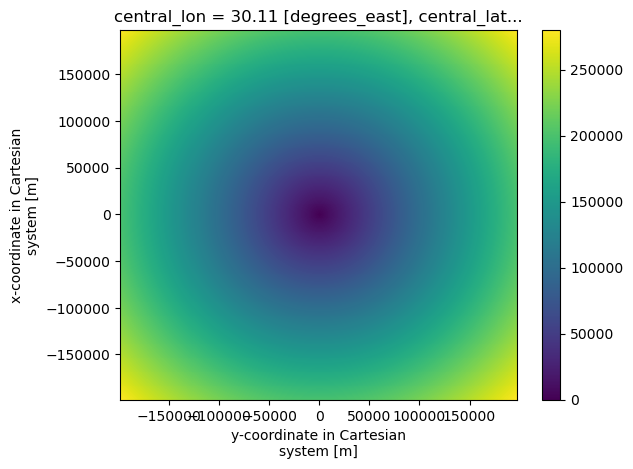

In [20]:
distance_from_centre_of_grid = np.sqrt((radar.x - radar.sel(x=centre_x, method="nearest").x)**2 + (radar.y - radar.sel(y=centre_y, method="nearest").y)**2)
distance_from_centre_of_grid.plot()

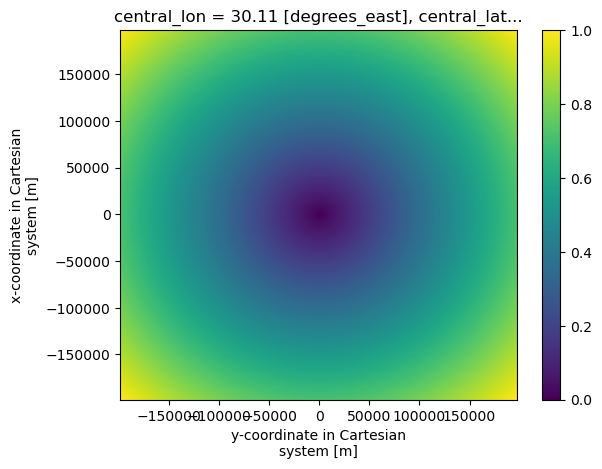

In [21]:
distance_from_centre_of_grid_norm = distance_from_centre_of_grid / distance_from_centre_of_grid.max()
distance_from_centre_of_grid_norm.plot()

In [22]:
distance_from_centre_of_grid_norm = distance_from_centre_of_grid_norm.to_dataset(name="norm_distance_from_instrument")

In [23]:
distance_from_centre_of_grid_norm.to_netcdf(os.path.join(output_dir, "distance_from_radar_instrument.nc"))

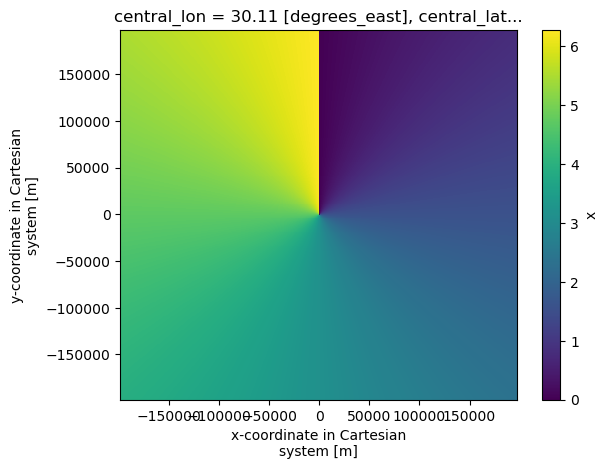

In [24]:
azimuthal_angle = np.arctan2((radar.x - radar.sel(x=centre_x, method="nearest").x), (radar.y - radar.sel(y=centre_y, method="nearest").y))
azimuthal_angle = azimuthal_angle % (2 * np.pi)
azimuthal_angle.plot(x="x", y="y")

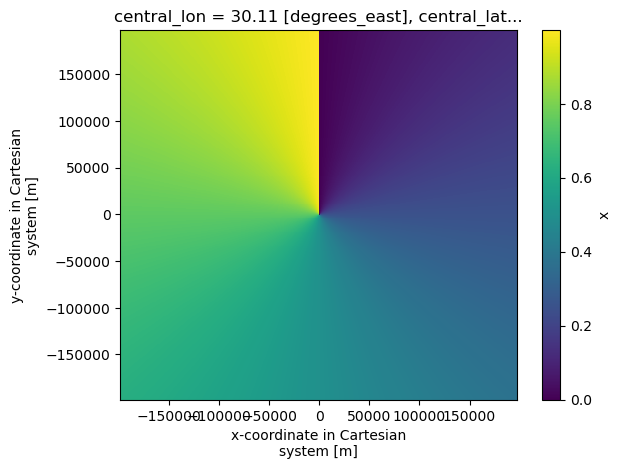

In [25]:
azimuthal_angle_norm = azimuthal_angle / (2 * np.pi)
azimuthal_angle_norm.plot(x="x", y="y")

In [26]:
azimuthal_angle_norm = azimuthal_angle_norm.to_dataset(name="norm_azimuthal_angle")

In [27]:
azimuthal_angle_norm.to_netcdf(os.path.join(output_dir, "azimuthal_angle.nc"))

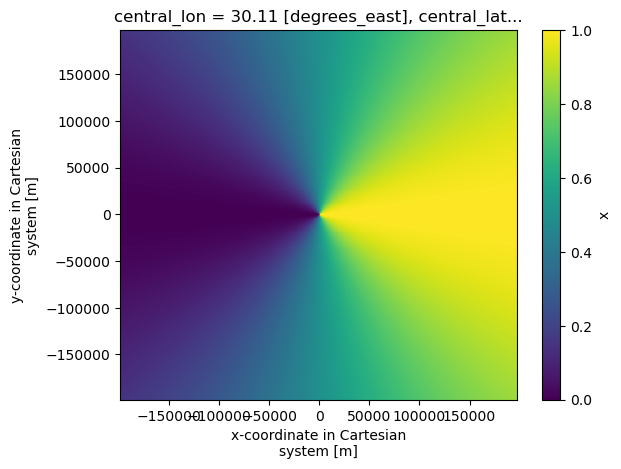

In [28]:
azimuthal_sin = (np.sin(azimuthal_angle) + 1) / 2
azimuthal_cos = (np.cos(azimuthal_angle) + 1) / 2
azimuthal_sin = azimuthal_sin % (2 * np.pi)
azimuthal_sin.plot(x="x", y="y")

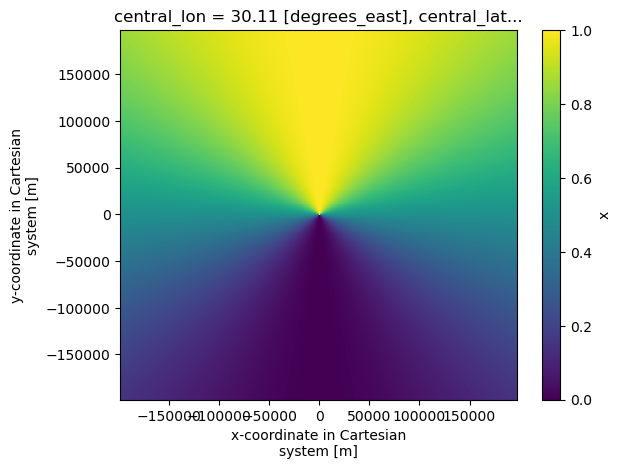

In [29]:
azimuthal_cos = azimuthal_cos % (2 * np.pi)
azimuthal_cos.plot(x="x", y="y")

In [30]:
azimuthal_sin_norm = azimuthal_sin.to_dataset(name="azimuthal_sin")
azimuthal_sin_norm.to_netcdf(os.path.join(output_dir, "azimuthal_sin.nc"))

azimuthal_cos_norm = azimuthal_cos.to_dataset(name="azimuthal_cos")
azimuthal_cos_norm.to_netcdf(os.path.join(output_dir, "azimuthal_cos.nc"))

In [31]:
501%19

7